# RFM vs. CellFlow on EB differentiation: 10, 20 and 30 time-selected PCs, fixed-Gaussian kernel

**Question.** How do CellFlow and RFM compare at the held-out intermediate days $t=0.25, 0.5, 0.75$ when the EB data are represented by the 10, 20 or 30 principal components that `data/eb_ot_v2.ipynb` selected for their time structure?

**Scenarios.** `data/eb_ot_v2.ipynb` fits a 50-component PCA on the benchmark's training cells (log-normalised, all 1,241 genes) and picks components by greedy forward selection on the kNN time structure. The 10-, 20- and 30-PC scenarios are its `pca.time_selected` sets in `data/eb_ot_v2/eb_scenarios.json`. The sets are nested, so the 10 PCs are part of the 20 and the 20 part of the 30.

**Models.** Both are trained only from the $t=0$ cells (source) to the $t=1$ cells (target) of the training split. The intermediate days are never seen in training.

| | Path | Coupling |
| --- | --- | --- |
| **CellFlow** (FM + Euclidean OT) | straight line, $u_t(x\mid x_1)=(x_1-x)/(1-t)$ | entropic OT on the coordinates |
| **RFM** (RFM + biharmonic OT) | biharmonic-distance geodesic, $u_t(x\mid x_1)=-\,d\,\nabla d/(\lVert\nabla d\rVert^2(1-t))$ | entropic OT in the Nyström biharmonic embedding |

**Kernel.** The biharmonic geometry uses the **fixed Gaussian** kernel: edge weight $\exp(-\lVert x-y\rVert^2/(2\sigma^2))$ with one global $\sigma$ (the median distance of the graph points to their 24 nearest neighbours), on the CkNN support $\lVert x-y\rVert^2<\delta^2\rho_x\rho_y$ with $k_\rho=24$ and $\delta=2$.

**Settings.** Everything else follows `riemannian_eb_scenarios_3d_fixed_gaussian.ipynb`: the same split (70 / 10 / 20% within each time point), graph (4,000 training cells from all five days), 32 biharmonic modes, network, optimizer, batch size, 1,000 iterations, OT $\varepsilon$, RFM interpolation (32 Euler steps, no clipping, speed cap 10 × the mean $t=0$ to $t=1$ distance) and ODE solver (Tsit5, tolerances $10^{-5}$, up to 100,000 steps).

**Repeats.** GPU training is not bit-reproducible: in the 3-D notebooks, the same CellFlow model gave validation energy² between 0.10 and 0.26 across four runs. Every model is therefore trained **three times** (seeds 2026, 2027, 2028), and the tables report the mean and the spread. Within a seed, both models start from the same network initialisation.

**Evaluation.** Each model integrates the held-out $t=0$ cells of the validation split (277 cells) and of the test split (531 cells) once, and the states at $t=0.25, 0.5, 0.75, 1$ are compared with the observed cells of that day in the same split. The metrics are the squared energy distance and $W_2$, both in the coordinates of the scenario. Two references bracket them: the unchanged source cells (doing nothing), and the training cells of that day (the sampling floor). Numbers are comparable between models within one scenario, not across scenarios, because the coordinates differ.

Run from `CellFlow/docs/notebooks`.

In [1]:
# 1 · imports and settings
import os

os.environ.setdefault("TQDM_DISABLE", "1")   # no per-iteration progress bars in the saved notebook
import json
import time as _time
import warnings

import anndata as ad
import diffrax
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
import optax
import pandas as pd
from IPython.display import display
from scipy.spatial.distance import cdist
from scipy.stats import spearmanr

from cellflow.ode_solver import RFMInterpolation
from riemannian_toys import cells, comparison, flows, kernels

warnings.simplefilter("ignore", FutureWarning)
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 30)

DATA_DIR = "/ictstr01/groups/ml01/workspace/markus.laengst/data/eb_ot_v2"
if not os.path.exists(DATA_DIR):   # the GPU nodes mount the same workspace under /lustre
    DATA_DIR = DATA_DIR.replace("/ictstr01/", "/lustre/", 1)

DIMS = (10, 20, 30)                 # time-selected PC sets of data/eb_ot_v2.ipynb
SEEDS = (2026, 2027, 2028)          # three training runs per model
CELLFLOW, RFM = "FM + Euclidean OT", "RFM + biharmonic OT"
MODELS = (CELLFLOW, RFM)
MODEL_STYLE = {CELLFLOW: {"color": "tab:pink", "marker": "o", "label": "CellFlow (FM + Euclidean OT)"},
               RFM: {"color": "tab:green", "marker": "s", "label": "RFM (RFM + biharmonic OT)"}}
EVAL_TIMES = np.array([0.0, 0.25, 0.5, 0.75, 1.0], dtype=np.float32)
INTERMEDIATE = (0.25, 0.5, 0.75)

# as in riemannian_eb_scenarios_3d_fixed_gaussian.ipynb
split_fractions, split_seed = {"train": 0.7, "val": 0.1, "test": 0.2}, 0
graph_max_cells, graph_seed = 4000, 0
kernel_name = "fixed Gaussian"
kernel_settings = {"density_k": 24, "delta": 2.0, "n_modes": 32, "laplacian_type": "unnormalized",
                   "spectral_weight_type": "biharmonic"}
ot_epsilon, batch_size, interpolation_steps, num_iterations = 0.05, 64, 32, 1000
source_time, target_time = 0.0, 1.0
target_key = "day_1"
max_ode_steps = 100_000
velocity_cap_factor = 10.0

architecture = {
    "condition_mode": "deterministic",
    "regularization": 0.0,
    "pooling": "attention_token",
    "pooling_kwargs": {},
    "layers_before_pool": {"transport": [{"layer_type": "mlp", "dims": (512, 512), "dropout_rate": 0.5}]},
    "layers_after_pool": [{"layer_type": "mlp", "dims": (512, 512), "dropout_rate": 0.1}],
    "condition_embedding_dim": 128,
    "cond_output_dropout": 0.3,
    "condition_encoder_kwargs": {},
    "pool_sample_covariates": True,
    "time_freqs": 1024,
    "time_encoder_dims": (512, 512),
    "time_encoder_dropout": 0.1,
    "hidden_dims": (512, 512),
    "hidden_dropout": 0.2,
    "conditioning": "film",
    "decoder_dims": (1024, 1024),
    "vf_act_fn": jax.nn.silu,
    "layer_norm_before_concatenation": False,
    "linear_projection_before_concatenation": False,
}
print("jax devices:", jax.devices())

jax devices: [CudaDevice(id=0)]


## The scenarios

In [2]:
# 2 · data, split and the three PC scenarios
obs = ad.read_h5ad(f"{DATA_DIR}/eb_prepared.h5ad", backed="r").obs.copy()
scen = json.load(open(f"{DATA_DIR}/eb_scenarios.json"))
pz = np.load(f"{DATA_DIR}/eb_pca.npz")
assert (pz["obs_names"] == obs.index.to_numpy(dtype=str)).all()

time = obs["experimental_time"].to_numpy(np.float64)
time_levels = np.unique(time)
split = cells.stratified_group_split(time, obs["duplicate_group"].astype(str).to_numpy(), split_fractions, split_seed)
display(cells.split_table(split, time))


def cells_at(s, split_name, t):
    return s["X"][(split == split_name) & np.isclose(time, t)]


S, scenario_rows = {}, {}
for k in DIMS:
    sel = scen["pca"]["time_selected"][str(k)]
    X = np.ascontiguousarray(pz["scores"][:, sel["pcs"]], dtype=np.float32)
    S[f"{k} PCs"] = {"X": X, "pcs": sel["pcs"], "labels": sel["labels"]}
    scenario_rows[f"{k} PCs"] = {
        "components": ", ".join(sel["labels"]),
        "share of PCA variance": float(pz["explained_variance_ratio"][sel["pcs"]].sum()),
        "kNN mean |dt| (train, from eb_ot_v2)": sel["metrics"]["abs_dt"],
        "kNN same-day share (train, from eb_ot_v2)": sel["metrics"]["same_time"],
    }
display(pd.DataFrame(scenario_rows).T)

time,0.0,0.25,0.5,0.75,1.0,All
split,,,,,,
train,1859,3062,2555,2711,2555,12742
val,266,437,365,387,365,1820
test,531,875,730,775,730,3641
All,2656,4374,3650,3873,3650,18203


,components,share of PCA variance,"kNN mean |dt| (train, from eb_ot_v2)","kNN same-day share (train, from eb_ot_v2)"
10 PCs,"PC1, PC2, PC4, PC5, PC6, PC7, PC8, PC9, PC10, ...",0.168708,0.0986,0.6687
20 PCs,"PC1, PC2, PC4, PC5, PC6, PC7, PC8, PC9, PC10, ...",0.212774,0.0917,0.6905
30 PCs,"PC1, PC2, PC4, PC5, PC6, PC7, PC8, PC9, PC10, ...",0.24618,0.0908,0.6931


## Graph and biharmonic geometry

`lambda_2`, the smallest non-zero eigenvalue of the graph Laplacian, measures how well the graph is connected; small values mean a bottleneck. In the 3-PC view the fixed Gaussian gave $\lambda_2 = 0.078$ and attached the sparse outer cells only weakly. The higher-dimensional views behave differently. Distances concentrate there, so the CkNN support links each graph point to a large share of the others, and $\sigma$ grows with the dimension.

In [3]:
# 3 · fixed-Gaussian graph, kernel and Nyström extension per scenario; RFM speed cap
train_ids = np.flatnonzero(split == "train")
graph_ids = np.sort(np.random.default_rng(graph_seed).choice(train_ids, graph_max_cells, replace=False))

geometry_rows = {}
for name, s in S.items():
    points, counts, inverse = cells.unique_points(s["X"][graph_ids])
    point_time = np.bincount(inverse, weights=time[graph_ids]) / counts
    models, fitted, _, fit_df = kernels.fit_kernel_profiles(points, {kernel_name: kernels.KERNEL_PROFILES[kernel_name]},
                                                            **kernel_settings)
    s.update(points=points, point_time=point_time, nystroem=models[kernel_name])
    s["cloud"] = cells.CellCloud(points, fitted[kernel_name])
    src, tgt = cells_at(s, "train", source_time), cells_at(s, "train", target_time)
    rng = np.random.default_rng(0)
    pair_dist = np.linalg.norm(src[rng.integers(len(src), size=5000)] - tgt[rng.integers(len(tgt), size=5000)], axis=1)
    s["velocity_cap"] = float(velocity_cap_factor * pair_dist.mean())
    s["m0"], s["m1"] = src.mean(0), tgt.mean(0)               # training means of the source and target days
    psi = np.asarray(s["nystroem"].Psi)
    fit = fit_df.loc[kernel_name]
    geometry_rows[name] = {
        "distinct graph points": len(points),
        "sigma": float(fitted[kernel_name].sigma),
        "edges": int(fit["edges"]),
        "mean neighbours per point": 2 * fit["edges"] / len(points),
        "components": int(fit["components"]),
        "min degree": fit["min_degree"], "median degree": fit["median_degree"], "lambda_2": fit["lambda_2"],
        **{f"|spearman(Psi_{j + 1}, time)|": abs(spearmanr(psi[:, j], point_time)[0]) for j in range(3)},
        **{f"{sp} cells in support": float(s["cloud"].contains(s["X"][split == sp]).mean()) for sp in ("val", "test")},
        "mean distance t=0 to t=1 cells": float(pair_dist.mean()),
        "RFM speed cap": s["velocity_cap"],
    }
display(pd.DataFrame(geometry_rows).round(4))

fixed Gaussian: fitted in 7.05s
fixed Gaussian: fitted in 8.24s
fixed Gaussian: fitted in 9.39s


,10 PCs,20 PCs,30 PCs
distinct graph points,4.000000e+03,4.000000e+03,4.000000e+03
sigma,5.708700e+00,8.992100e+00,1.129480e+01
edges,1.493305e+06,3.400074e+06,5.158764e+06
mean neighbours per point,7.466525e+02,1.700037e+03,2.579382e+03
components,1.000000e+00,1.000000e+00,1.000000e+00
min degree,1.686080e+01,5.157470e+01,8.447750e+01
median degree,1.492968e+02,3.550925e+02,6.206025e+02
lambda_2,3.287700e+00,1.550350e+01,4.356620e+01
"|spearman(Psi_1, time)|",6.884000e-01,7.211000e-01,7.119000e-01
"|spearman(Psi_2, time)|",2.622000e-01,2.732000e-01,2.094000e-01


## The RFM reference paths

Before training, the exact RFM conditional field shows what RFM is asked to learn. For each scenario, the cell below integrates it by 800 Euler steps to $t=0.99$ from 13 training graph points at $t=0$ towards $x_1$, the medoid of the graph points at $t=1$. The first start is $x_0$, the medoid at $t=0$; the other 12 are random.

- **length / straight:** path length against the straight line.
- **end error:** distance to $x_1$ at $t=0.99$. The exact field should arrive.
- **share covered at $t$:** $1 - \lVert x_t - x_1\rVert / \lVert x_0 - x_1\rVert$, the Euclidean share of the way done at time $t$. The straight FM path covers exactly $t$. RFM makes the *biharmonic* distance fall linearly, so its Euclidean progress can run ahead of or behind $t$. That timing is what the intermediate days test.

In [4]:
# 4 · reference RFM paths per scenario
def medoid(points):
    return points[cdist(points, points).mean(axis=1).argmin()]


ref_times = np.linspace(0.0, 0.99, 801)
reference_rows = {}
for name, s in S.items():
    pts, pt = s["points"], s["point_time"]
    at0, at1 = pts[np.isclose(pt, source_time)], pts[np.isclose(pt, target_time)]
    x0, x1 = medoid(at0), medoid(at1)
    starts = np.vstack([x0[None, :], at0[np.random.default_rng(2026).choice(len(at0), 12, replace=False)]])
    interp = RFMInterpolation(s["nystroem"], projection_fn=None, max_velocity_norm=s["velocity_cap"])
    path, _ = kernels.integrate_euler_paths(interp, starts, x1, 0.99, 800)
    path = np.swapaxes(np.asarray(path), 0, 1)                                       # (13, 801, d)
    straight = np.linalg.norm(starts - x1, axis=1)
    length = np.linalg.norm(np.diff(path, axis=1), axis=-1).sum(axis=1)
    covered = 1.0 - np.linalg.norm(path - x1, axis=-1) / straight[:, None]           # (13, 801)
    s["reference_covered"] = covered.mean(0)
    reference_rows[name] = {
        "pair: length / straight": float(length[0] / straight[0]),
        "13 paths: length / straight (mean)": float(np.mean(length / straight)),
        "pair: end error (t=0.99)": float(np.linalg.norm(path[0, -1] - x1)),
        "13 paths: end error / straight (mean)": float(np.mean(np.linalg.norm(path[:, -1] - x1, axis=1) / straight)),
        **{f"share covered at t={t:g} (mean)": float(covered[:, np.argmin(np.abs(ref_times - t))].mean())
           for t in INTERMEDIATE},
        "max support ratio": float(s["cloud"].support_ratio(path).max()),
    }
display(pd.DataFrame(reference_rows).round(3))

,10 PCs,20 PCs,30 PCs
pair: length / straight,1.700,1.436,1.089
13 paths: length / straight (mean),1.569,1.298,0.969
pair: end error (t=0.99),7.259,9.241,13.368
13 paths: end error / straight (mean),0.308,0.475,0.664
share covered at t=0.25 (mean),0.214,0.194,0.136
share covered at t=0.5 (mean),0.316,0.316,0.244
share covered at t=0.75 (mean),0.470,0.419,0.317
max support ratio,0.476,0.570,0.593


## Training and evaluation

For every scenario and seed, the cell trains CellFlow and RFM, integrates the held-out $t=0$ cells of the validation and test splits through $t=0.25, 0.5, 0.75, 1$, and scores each state against the observed cells of that day. It also records the **progress** of each predicted state: the mean projection onto the axis from the training $t=0$ mean to the training $t=1$ mean, scaled so that $t=0$ is 0 and $t=1$ is 1. The observed days have their own progress values, so this shows whether a model's cells are ahead of or behind the data at each time.

In [5]:
# 5 · train both models three times per scenario; evaluate on validation and test cells at every day
def integrate(model, starts, save_times):
    # learned flow from the starts, saved at save_times (Tsit5, rtol = atol = 1e-5, raised step limit)
    state, condition, encoder_noise = flows.inference_inputs(model)

    def velocity(t, y, params):
        return state.apply_fn({"params": params}, t, y, condition, encoder_noise, train=False)[0]

    def one(params, y0):
        sol = diffrax.diffeqsolve(diffrax.ODETerm(velocity), diffrax.Tsit5(), t0=0.0, t1=1.0, dt0=None, y0=y0, args=params,
                                  stepsize_controller=diffrax.PIDController(rtol=1e-5, atol=1e-5),
                                  saveat=diffrax.SaveAt(ts=jnp.asarray(save_times)), max_steps=max_ode_steps)
        return sol.ys, sol.stats["num_steps"]

    states, steps = jax.jit(jax.vmap(one, in_axes=(None, 0)))(state.params, jnp.asarray(starts, dtype=jnp.float32))
    states = np.asarray(states)
    assert np.all(np.isfinite(states))
    return states, np.asarray(steps)


def progress(s, Y):
    axis = s["m1"] - s["m0"]
    return float(np.mean((np.asarray(Y) - s["m0"]) @ axis) / (axis @ axis))


metric_cols = ["energy_distance_squared", "wasserstein_2", "mean_error_to_target", "unsupported_fraction"]
reference_records, records, run_records = [], [], []
for name, s in S.items():
    for split_name in ("val", "test"):
        source = cells_at(s, split_name, source_time)
        for t in EVAL_TIMES[1:]:
            observed = cells_at(s, split_name, t)
            table = cells.metric_table({"unchanged source": source, "floor (training cells of the day)": cells_at(s, "train", t)},
                                       observed, s["cloud"])
            for ref, row in table.iterrows():
                reference_records.append({"view": name, "split": split_name, "time": float(t), "cloud": ref,
                                          **row[metric_cols].to_dict()})
            reference_records.append({"view": name, "split": split_name, "time": float(t), "cloud": "observed",
                                      "progress": progress(s, observed)})

    src, tgt = cells_at(s, "train", source_time), cells_at(s, "train", target_time)
    train_adata = flows.make_toy_adata(src, tgt, target_key)
    embed = jax.jit(jax.vmap(s["nystroem"].extend_point))
    match_biharmonic = flows.make_entropic_match_fn(ot_epsilon, embed=embed)
    match_euclidean = flows.make_entropic_match_fn(ot_epsilon)
    for seed in SEEDS:
        print(f"===== {name}, seed {seed} =====", flush=True)
        rfm = flows.prepare_toy_model(
            train_adata, "otrfm", target_key, **architecture, match_fn=match_biharmonic, nystroem=s["nystroem"],
            optimizer=optax.adam(1e-3), seed=seed,
            solver_kwargs={"interpolation_steps": interpolation_steps, "projection_fn": None,
                           "project_to_manifold": False, "max_velocity_norm": s["velocity_cap"]},
        )
        models = {CELLFLOW: flows.build_matched_model(rfm, train_adata, "otfm", match_euclidean, target_key, seed),
                  RFM: rfm}
        losses, seconds = {}, {}
        comparison.train_untrained(models, losses, seconds, num_iterations, batch_size)
        starts = {sp: cells_at(s, sp, source_time) for sp in ("val", "test")}
        for m, model in models.items():
            # one solve for the validation and test source cells together
            all_states, steps = integrate(model, np.vstack(list(starts.values())), EVAL_TIMES)
            offset = 0
            for split_name, start in starts.items():
                states = all_states[offset:offset + len(start)]
                offset += len(start)
                for k, t in enumerate(EVAL_TIMES[1:], start=1):
                    row = cells.metric_table({m: states[:, k]}, cells_at(s, split_name, t), s["cloud"]).loc[m]
                    records.append({"view": name, "seed": seed, "model": m, "split": split_name, "time": float(t),
                                    **row[metric_cols].to_dict(), "progress": progress(s, states[:, k])})
            run_records.append({"view": name, "seed": seed, "model": m, "training s": seconds[m],
                                "mean loss, last 25 steps": float(np.mean(losses[m][-25:])),
                                "adaptive steps per cell (median)": float(np.median(steps)),
                                "adaptive steps per cell (max)": int(steps.max())})
        del models, rfm

results = pd.DataFrame(records)
references = pd.DataFrame(reference_records)
runs = pd.DataFrame(run_records)
print(f"{len(results)} evaluation rows from {len(runs)} trained models")

===== 10 PCs, seed 2026 =====
[########################################] | 100% Completed | 101.74 ms
[########################################] | 100% Completed | 101.20 ms
[########################################] | 100% Completed | 101.85 ms
[########################################] | 100% Completed | 102.65 ms
[########################################] | 100% Completed | 101.78 ms
Training FM + Euclidean OT
FM + Euclidean OT: 34.0s; mean loss first 25 20.77138, last 25 8.70010
Training RFM + biharmonic OT
RFM + biharmonic OT: 107.7s; mean loss first 25 225.36055, last 25 128.12918
===== 10 PCs, seed 2027 =====
[########################################] | 100% Completed | 101.73 ms
[########################################] | 100% Completed | 101.00 ms
[########################################] | 100% Completed | 102.13 ms
[########################################] | 100% Completed | 102.48 ms
Training FM + Euclidean OT
FM + Euclidean OT: 10.1s; mean loss first 25 17.62112, last 2

## Results at every day

Mean over the three seeds, with the standard deviation in brackets. "RFM / CellFlow" is the ratio of the means; "RFM better" counts the seeds in which RFM beats CellFlow, paired by seed (both models share the initialisation). The test split has 531 source cells and 750–1,150 observed cells per day; the validation split about half as many.

In [6]:
# 6 · tables: energy² and W2 per scenario, day and split
def fmt(mean, sd):
    return f"{mean:.3f} ({sd:.3f})"


def comparison_table(metric, split_name):
    r = results[results.split == split_name]
    ref = references[(references.split == split_name) & references.cloud.isin(["unchanged source", "floor (training cells of the day)"])]
    rows = {}
    for (view, t), g in r.groupby(["view", "time"], sort=False):
        cf = g[g.model == CELLFLOW].set_index("seed")[metric]
        rf = g[g.model == RFM].set_index("seed")[metric]
        refs = ref[(ref.view == view) & (ref.time == t)].set_index("cloud")[metric]
        rows[(view, t)] = {
            "CellFlow": fmt(cf.mean(), cf.std()), "RFM": fmt(rf.mean(), rf.std()),
            "RFM / CellFlow": rf.mean() / cf.mean(), "RFM better (of 3 seeds)": int((rf < cf.loc[rf.index]).sum()),
            "unchanged source": refs["unchanged source"], "floor": refs["floor (training cells of the day)"],
        }
    return pd.DataFrame.from_dict(rows, orient="index").rename_axis(["view", "time"])


for metric, label in [("energy_distance_squared", "energy²"), ("wasserstein_2", "W2")]:
    for split_name in ("test", "val"):
        print(f"===== {label}, {split_name} split =====")
        display(comparison_table(metric, split_name).round(3))

===== energy², test split =====


CellFlow            RFM  RFM / CellFlow  RFM better (of 3 seeds)  unchanged source  floor
view   time                                                                                                
10 PCs 0.25  3.956 (0.052)  2.876 (0.044)           0.727                        3             6.441  0.032
       0.50  4.026 (0.092)  5.111 (0.248)           1.269                        0            11.886  0.051
       0.75  2.542 (0.055)  5.069 (0.081)           1.994                        0            14.413  0.032
       1.00  0.105 (0.028)  4.241 (0.322)          40.456                        0            17.044  0.025
20 PCs 0.25  3.687 (0.011)  2.514 (0.117)           0.682                        3             5.955  0.032
       0.50  3.654 (0.043)  3.405 (0.444)           0.932                        2            10.813  0.050
       0.75  2.231 (0.130)  3.260 (0.718)           1.461                        0            12.950  0.033
       1.00  0.243 (0.013)  2.536 (0.387)          10.444                        0            15.426  0.036
30 PCs 0.25  3.488 (0.035)  2.274 (0.137)           0.652                        3             5.541  0.035
       0.50  3.445 (0.081)  2.466 (0.113)           0.716                        3            10.057  0.053
       0.75  2.101 (0.130)  2.462 (0.032)           1.172                        0            12.090  0.038
       1.00  0.319 (0.037)  3.435 (0.163)          10.780                        0            14.413  0.037

===== energy², val split =====


CellFlow            RFM  RFM / CellFlow  RFM better (of 3 seeds)  unchanged source  floor
view   time                                                                                                
10 PCs 0.25  3.895 (0.051)  2.787 (0.055)           0.716                        3             6.079  0.042
       0.50  4.080 (0.070)  5.262 (0.358)           1.289                        0            11.678  0.065
       0.75  2.807 (0.039)  5.339 (0.195)           1.902                        0            14.412  0.048
       1.00  0.190 (0.066)  4.248 (0.270)          22.305                        0            16.749  0.050
20 PCs 0.25  3.585 (0.007)  2.476 (0.051)           0.690                        3             5.601  0.051
       0.50  3.713 (0.046)  3.565 (0.434)           0.960                        2            10.634  0.072
       0.75  2.509 (0.119)  3.412 (0.643)           1.360                        0            12.915  0.052
       1.00  0.249 (0.004)  2.518 (0.369)          10.094                        0            15.078  0.057
30 PCs 0.25  3.415 (0.038)  2.300 (0.120)           0.673                        3             5.222  0.057
       0.50  3.523 (0.070)  2.585 (0.283)           0.734                        3             9.934  0.075
       0.75  2.373 (0.136)  2.757 (0.039)           1.161                        0            12.065  0.054
       1.00  0.288 (0.035)  3.434 (0.182)          11.937                        0            14.061  0.062

===== W2, test split =====


CellFlow             RFM  RFM / CellFlow  RFM better (of 3 seeds)  unchanged source   floor
view   time                                                                                                   
10 PCs 0.25  11.258 (0.042)  10.498 (0.045)           0.932                        3            13.913   5.092
       0.50  11.522 (0.167)  13.609 (0.146)           1.181                        0            18.483   5.431
       0.75  10.056 (0.208)  13.614 (0.179)           1.354                        0            20.024   5.456
       1.00   6.335 (0.112)  11.500 (0.619)           1.815                        0            20.665   5.554
20 PCs 0.25  13.370 (0.039)  12.746 (0.093)           0.953                        3            15.804   8.167
       0.50  13.542 (0.187)  14.584 (0.306)           1.077                        0            20.086   8.811
       0.75  12.273 (0.284)  14.412 (0.580)           1.174                        0            21.462   8.651
       1.00   9.620 (0.066)  12.806 (0.478)           1.331                        0            22.223   8.935
30 PCs 0.25  14.982 (0.023)  14.052 (0.197)           0.938                        3            17.153  10.305
       0.50  15.308 (0.153)  14.722 (0.502)           0.962                        3            21.281  11.237
       0.75  14.424 (0.201)  14.627 (0.146)           1.014                        1            22.675  11.045
       1.00  12.201 (0.063)  15.737 (0.154)           1.290                        0            23.337  11.266

===== W2, val split =====


CellFlow             RFM  RFM / CellFlow  RFM better (of 3 seeds)  unchanged source   floor
view   time                                                                                                   
10 PCs 0.25  11.476 (0.039)  10.702 (0.058)           0.933                        3            13.870   5.671
       0.50  12.476 (0.154)  14.456 (0.275)           1.159                        0            19.131   6.057
       0.75  10.658 (0.141)  13.853 (0.093)           1.300                        0            20.160   6.083
       1.00   6.842 (0.066)  11.447 (0.545)           1.673                        0            20.375   5.977
20 PCs 0.25  13.521 (0.039)  12.879 (0.081)           0.953                        3            15.743   8.698
       0.50  14.411 (0.203)  15.379 (0.326)           1.067                        0            20.699   9.349
       0.75  12.855 (0.226)  14.647 (0.516)           1.139                        0            21.656   9.401
       1.00  10.081 (0.081)  12.974 (0.376)           1.287                        0            21.906   9.399
30 PCs 0.25  15.146 (0.017)  14.239 (0.181)           0.940                        3            17.100  10.941
       0.50  16.218 (0.133)  15.505 (0.791)           0.956                        3            21.917  11.719
       0.75  15.039 (0.156)  15.174 (0.174)           1.009                        1            22.905  11.802
       1.00  12.639 (0.012)  15.896 (0.211)           1.258                        0            23.111  11.817

In [7]:
# 7 · summary over the three intermediate days (mean of the per-day values), per seed and on average
inter = results[results.time.isin(INTERMEDIATE)]
per_seed = inter.groupby(["view", "split", "model", "seed"])[["energy_distance_squared", "wasserstein_2"]].mean()
summary = per_seed.groupby(["view", "split", "model"]).agg(["mean", "std"])
summary.columns = [f"{m} {stat}" for m, stat in summary.columns]
wins = (per_seed.xs(RFM, level="model") < per_seed.xs(CELLFLOW, level="model")).groupby(["view", "split"]).sum()
wins.columns = [f"RFM better: {c} (of 3 seeds)" for c in wins.columns]
display(summary.round(3))
display(wins)
endpoint = results[results.time == 1.0].groupby(["view", "split", "model"])[["energy_distance_squared", "wasserstein_2"]].agg(["mean", "std"])
endpoint.columns = [f"t=1 {m} {stat}" for m, stat in endpoint.columns]
display(endpoint.round(3))
display(runs.groupby(["view", "model"])[["training s", "mean loss, last 25 steps", "adaptive steps per cell (median)",
                                         "adaptive steps per cell (max)"]].mean().round(1))

energy_distance_squared mean  energy_distance_squared std  wasserstein_2 mean  wasserstein_2 std
view   split model                                                                                                                
10 PCs test  FM + Euclidean OT                           3.508                        0.063              10.945              0.139
             RFM + biharmonic OT                         4.352                        0.096              12.574              0.054
       val   FM + Euclidean OT                           3.594                        0.032              11.537              0.109
             RFM + biharmonic OT                         4.463                        0.151              13.004              0.055
20 PCs test  FM + Euclidean OT                           3.191                        0.061              13.062              0.169
             RFM + biharmonic OT                         3.059                        0.410              13.914              0.289
       val   FM + Euclidean OT                           3.269                        0.057              13.595              0.153
             RFM + biharmonic OT                         3.151                        0.366              14.301              0.256
30 PCs test  FM + Euclidean OT                           3.011                        0.080              14.904              0.123
             RFM + biharmonic OT                         2.401                        0.056              14.467              0.270
       val   FM + Euclidean OT                           3.104                        0.079              15.468              0.100
             RFM + biharmonic OT                         2.547                        0.085              14.973              0.367

RFM better: energy_distance_squared (of 3 seeds)  RFM better: wasserstein_2 (of 3 seeds)
view   split                                                                                          
10 PCs test                                                  0                                       0
       val                                                   0                                       0
20 PCs test                                                  2                                       0
       val                                                   2                                       0
30 PCs test                                                  3                                       3
       val                                                   3                                       3

t=1 energy_distance_squared mean  t=1 energy_distance_squared std  t=1 wasserstein_2 mean  t=1 wasserstein_2 std
view   split model                                                                                                                                
10 PCs test  FM + Euclidean OT                               0.105                            0.028                   6.335                  0.112
             RFM + biharmonic OT                             4.241                            0.322                  11.500                  0.619
       val   FM + Euclidean OT                               0.190                            0.066                   6.842                  0.066
             RFM + biharmonic OT                             4.248                            0.270                  11.447                  0.545
20 PCs test  FM + Euclidean OT                               0.243                            0.013                   9.620                  0.066
             RFM + biharmonic OT                             2.536                            0.387                  12.806                  0.478
       val   FM + Euclidean OT                               0.249                            0.004                  10.081                  0.081
             RFM + biharmonic OT                             2.518                            0.369                  12.974                  0.376
30 PCs test  FM + Euclidean OT                               0.319                            0.037                  12.201                  0.063
             RFM + biharmonic OT                             3.435                            0.163                  15.737                  0.154
       val   FM + Euclidean OT                               0.288                            0.035                  12.639                  0.012
             RFM + biharmonic OT                             3.434                            0.182                  15.896                  0.211

training s  mean loss, last 25 steps  adaptive steps per cell (median)  adaptive steps per cell (max)
view   model                                                                                                                     
10 PCs FM + Euclidean OT          18.2                       8.3                             594.3                          780.3
       RFM + biharmonic OT       106.6                     129.9                             812.0                         1117.3
20 PCs FM + Euclidean OT          11.2                       6.6                             568.7                          719.0
       RFM + biharmonic OT       237.2                      70.4                             695.0                          940.3
30 PCs FM + Euclidean OT          12.3                       5.8                             552.0                          678.3
       RFM + biharmonic OT       257.9                      36.0                             678.7                          953.3

## Figures

**Error against time.** One column per scenario.
- Thin lines connect the seed means; the small markers are the three seeds.
- Grey dashed: the unchanged source. Grey dotted: the sampling floor.
- Energy² is on a log scale, because the unchanged source is far above the models.

**Progress against time.** The observed days (black) and both models' predicted states, projected on the axis from the $t=0$ mean to the $t=1$ mean. A model above the black line is ahead of the data at that time; below it, behind.

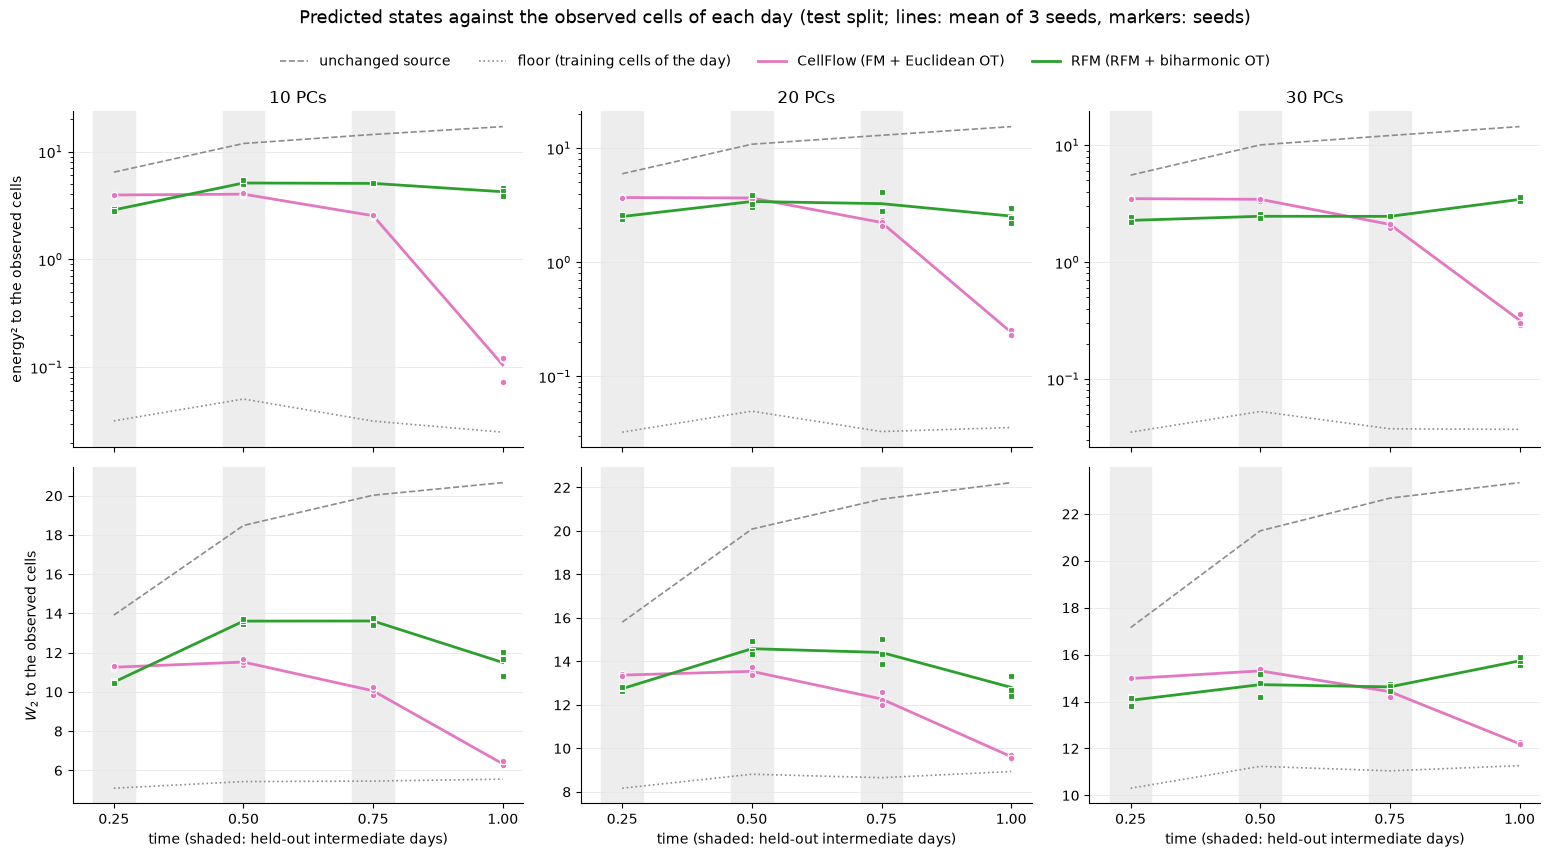

In [8]:
# 8 · error against time per scenario (test split)
def plot_metric_rows(split_name="test"):
    views = list(S)
    rows = [("energy_distance_squared", "energy² to the observed cells", True), ("wasserstein_2", "$W_2$ to the observed cells", False)]
    fig, axes = plt.subplots(len(rows), len(views), figsize=(5.2 * len(views), 8.2), sharex=True, squeeze=False)
    r_all = results[results.split == split_name]
    ref_all = references[references.split == split_name]
    for c, view in enumerate(views):
        for r, (metric, ylabel, log) in enumerate(rows):
            ax = axes[r, c]
            ref = ref_all[ref_all.view == view]
            for cloud, ls in [("unchanged source", "--"), ("floor (training cells of the day)", ":")]:
                g = ref[ref.cloud == cloud].sort_values("time")
                ax.plot(g.time, g[metric], color="0.55", lw=1.2, ls=ls, label=cloud)
            for m in MODELS:
                g = r_all[(r_all.view == view) & (r_all.model == m)]
                st = MODEL_STYLE[m]
                means = g.groupby("time")[metric].mean()
                ax.plot(means.index, means.values, color=st["color"], lw=2, label=st["label"])
                ax.scatter(g.time, g[metric], color=st["color"], marker=st["marker"], s=22, edgecolors="white",
                           linewidths=0.8, zorder=3)
            for t in INTERMEDIATE:
                ax.axvspan(t - 0.04, t + 0.04, color="0.93", zorder=0)
            if log:
                ax.set_yscale("log")
            ax.set_xticks(EVAL_TIMES[1:])
            ax.grid(axis="y", color="0.9", lw=0.6)
            ax.spines[["top", "right"]].set_visible(False)
            if r == 0:
                ax.set_title(view, fontsize=12)
            if c == 0:
                ax.set_ylabel(ylabel)
            if r == len(rows) - 1:
                ax.set_xlabel("time (shaded: held-out intermediate days)")
    handles, labels = axes[0, 0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="upper center", ncol=4, frameon=False, fontsize=10, bbox_to_anchor=(0.5, 1.0))
    fig.suptitle(f"Predicted states against the observed cells of each day ({split_name} split; lines: mean of 3 seeds, markers: seeds)",
                 y=1.04, fontsize=13)
    fig.tight_layout()
    plt.show()


plot_metric_rows("test")

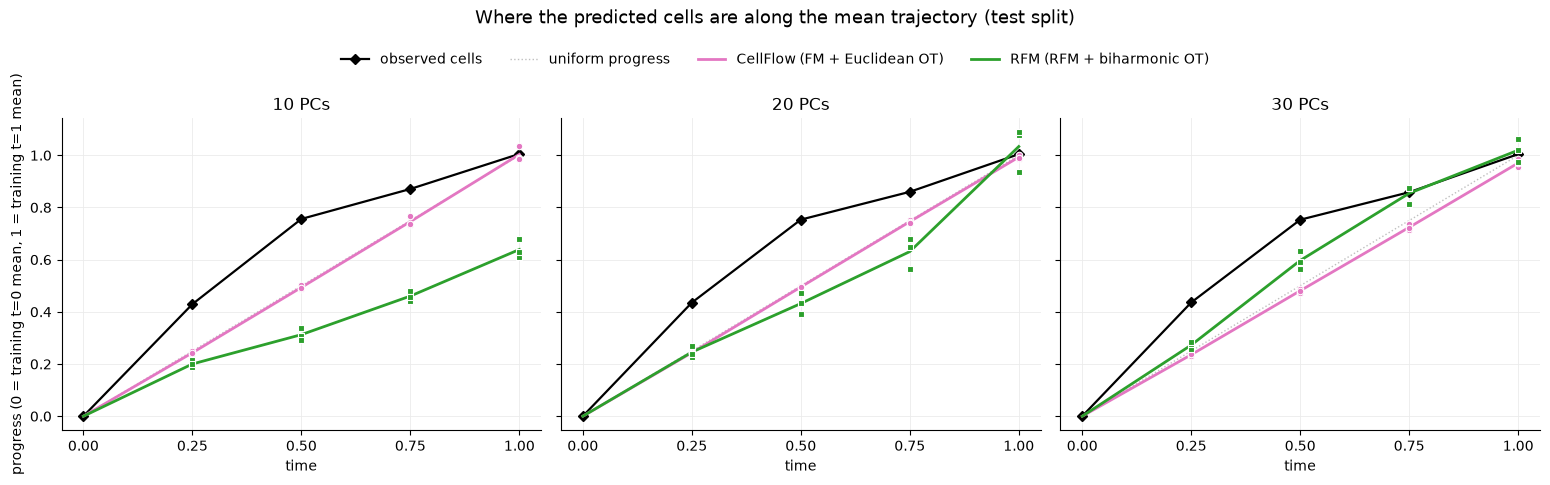

time                         0.25   0.50   0.75   1.00
view   model                                          
10 PCs FM + Euclidean OT    0.243  0.494  0.746  1.003
       RFM + biharmonic OT  0.200  0.313  0.460  0.639
       observed             0.430  0.756  0.871  1.005
20 PCs FM + Euclidean OT    0.243  0.495  0.746  0.993
       RFM + biharmonic OT  0.246  0.432  0.631  1.033
       observed             0.435  0.753  0.860  1.004
30 PCs FM + Euclidean OT    0.236  0.481  0.724  0.970
       RFM + biharmonic OT  0.273  0.597  0.854  1.019
       observed             0.436  0.753  0.858  1.004

In [9]:
# 9 · progress along the t=0 → t=1 mean axis (test split)
views = list(S)
fig, axes = plt.subplots(1, len(views), figsize=(5.2 * len(views), 4.4), sharey=True, squeeze=False)
for c, view in enumerate(views):
    ax = axes[0, c]
    obs_prog = references[(references.view == view) & (references.split == "test") & (references.cloud == "observed")].sort_values("time")
    ax.plot([0.0, *obs_prog.time], [0.0, *obs_prog.progress], color="black", lw=1.6, marker="D", ms=5, label="observed cells")
    ax.plot([0, 1], [0, 1], color="0.75", lw=1, ls=":", label="uniform progress")
    for m in MODELS:
        g = results[(results.view == view) & (results.split == "test") & (results.model == m)]
        st = MODEL_STYLE[m]
        means = g.groupby("time")["progress"].mean()
        ax.plot([0.0, *means.index], [0.0, *means.values], color=st["color"], lw=2, label=st["label"])
        ax.scatter(g.time, g.progress, color=st["color"], marker=st["marker"], s=22, edgecolors="white", linewidths=0.8, zorder=3)
    ax.set_xticks(EVAL_TIMES)
    ax.grid(color="0.92", lw=0.6)
    ax.spines[["top", "right"]].set_visible(False)
    ax.set_title(view, fontsize=12)
    ax.set_xlabel("time")
    if c == 0:
        ax.set_ylabel("progress (0 = training t=0 mean, 1 = training t=1 mean)")
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=4, frameon=False, fontsize=10, bbox_to_anchor=(0.5, 1.02))
fig.suptitle("Where the predicted cells are along the mean trajectory (test split)", y=1.09, fontsize=13)
fig.tight_layout()
plt.show()

prog = results[results.split == "test"].groupby(["view", "model", "time"])["progress"].mean().unstack("time")
obs_prog = references[(references.split == "test") & (references.cloud == "observed")].pivot(index="view", columns="time", values="progress")
obs_prog.index = pd.MultiIndex.from_product([obs_prog.index, ["observed"]], names=["view", "model"])
display(pd.concat([prog, obs_prog]).sort_index().round(3))

## Results

All numbers are means over three seeds on the **test split**. The validation split gives the same picture, with every ranking the same. "Robust" below means all three seed pairs agree and the gap is much larger than the seed spread.

**Geometry.** The fixed Gaussian gives a connected, well-conditioned graph in all three scenarios ($\lambda_2$ = 3.3, 15.5, 43.6; no zero-weight edges), unlike the 3-gene view. It is also very dense: each graph point is linked to 750–2,600 of the 4,000 points. The first biharmonic coordinate follows time ($|\rho|$ ≈ 0.7). The exact RFM reference field, however, does not reach its target. At $t=0.99$ the reference paths still have 31%, 48% and 66% of the straight-line distance to go (10, 20, 30 PCs), and at $t=0.5$ they have covered only 24–32% of it.

**Energy² to the observed cells (test).** The last column counts the seeds in which RFM beats CellFlow.

| Scenario | $t$ | CellFlow | RFM | RFM / CellFlow | RFM better |
| --- | --- | --- | --- | --- | --- |
| 10 PCs | 0.25 | 3.96 | 2.88 | 0.73 | 3 / 3 |
| | 0.5 | 4.03 | 5.11 | 1.27 | 0 / 3 |
| | 0.75 | 2.54 | 5.07 | 1.99 | 0 / 3 |
| | 1 | 0.11 | 4.24 | 40 | 0 / 3 |
| 20 PCs | 0.25 | 3.69 | 2.51 | 0.68 | 3 / 3 |
| | 0.5 | 3.65 | 3.41 | 0.93 | 2 / 3 |
| | 0.75 | 2.23 | 3.26 | 1.46 | 0 / 3 |
| | 1 | 0.24 | 2.54 | 10 | 0 / 3 |
| 30 PCs | 0.25 | 3.49 | 2.27 | 0.65 | 3 / 3 |
| | 0.5 | 3.45 | 2.47 | 0.72 | 3 / 3 |
| | 0.75 | 2.10 | 2.46 | 1.17 | 0 / 3 |
| | 1 | 0.32 | 3.44 | 11 | 0 / 3 |

For scale: the unchanged source is at 5.5–17, and the sampling floor at 0.03–0.05.

- **$t=0.25$: RFM is better in every scenario** (by 27–35%, robust).
- **$t=0.5$: it depends on the dimension.** CellFlow is better with 10 PCs and RFM with 30 PCs (both robust). With 20 PCs they tie within the RFM seed spread (± 0.44).
- **$t=0.75$: CellFlow is better in every scenario** (robust). The gap shrinks with dimension: 2.0×, 1.5×, 1.2×.
- **Mean over the three days:** CellFlow ahead with 10 PCs (3.51 vs 4.35), a tie with 20 PCs (3.19 vs 3.06 ± 0.41), RFM ahead with 30 PCs (3.01 vs 2.40; also in $W_2$, 14.9 vs 14.5, all seeds).
- **$W_2$** agrees, with smaller ratios (0.93–1.35 at the intermediate days). The one exception is 20 PCs at $t=0.5$, already a tie in energy², where $W_2$ favours CellFlow in all seeds.
- **$t=1$: CellFlow is 10–40× better**, as in the 3-PC notebooks.
- **Neither model tracks the intermediate days closely.** Their energy² of 2–5 is still 17–63% of what doing nothing gives and 50–160× the sampling floor. For CellFlow it is 7–40× its own error at $t=1$.

**Why: the timing of the data.** Both models only see $t=0$ and $t=1$, so their speed along the way is an assumption, not something learned from data. The progress figure shows how far each one's predicted cells are along the axis from the $t=0$ mean to the $t=1$ mean.

| Progress at | $t=0.25$ | $t=0.5$ | $t=0.75$ | $t=1$ |
| --- | --- | --- | --- | --- |
| observed cells | 0.43–0.44 | 0.75–0.76 | 0.86–0.87 | 1.00 |
| CellFlow (all scenarios) | 0.24 | 0.48–0.50 | 0.72–0.75 | 0.97–1.00 |
| RFM, 10 PCs | 0.20 | 0.31 | 0.46 | 0.64 |
| RFM, 20 PCs | 0.25 | 0.43 | 0.63 | 1.03 |
| RFM, 30 PCs | 0.27 | 0.60 | 0.85 | 1.02 |

- **The data are front-loaded.** Three quarters of the mean shift has happened by $t=0.5$.
- **CellFlow moves at constant speed by construction.** Its cells are far behind at $t=0.25$ and $t=0.5$, and nearly on time at $t=0.75$. That is why its intermediate error is flat at first and then drops.
- **RFM's speed depends on the geometry.** With 10 PCs it is slower than CellFlow throughout and does not even reach the target (0.64 at $t=1$). With 30 PCs it is ahead of uniform and matches the data at $t=0.75$. This explains why RFM improves with dimension at $t=0.5$ and $t=0.75$.
- **Timing is not the whole story.**
  - RFM wins at $t=0.25$ even where its progress equals CellFlow's (20 PCs: 0.25 vs 0.24). Its early states must therefore be closer in shape. This notebook does not test why.
  - Conversely, with 30 PCs RFM is on time at $t=0.75$ (0.85 vs 0.86) and still loses to CellFlow there. Its predicted distributions are worse in shape, as its 10× larger error at $t=1$ shows.

**Cost.** RFM training takes 107–258 s against 11–18 s for CellFlow on one GPU (6–21×), growing with the dimension. Prediction needs 1.2–1.4× more adaptive ODE steps.

**Bottom line**

- **CellFlow is clearly better at the endpoint it is trained for.**
- **At the held-out intermediate days, RFM is better early ($t=0.25$) and CellFlow late ($t=0.75$).** The overall winner at the intermediate days changes with the dimension: CellFlow with 10 PCs, a tie with 20, RFM with 30.
- **Both models are far from the observed intermediate distributions.** These intermediate-day comparisons mostly measure how well each model's implicit timing matches the data's front-loaded timing, not how well it learns the geometry. The 3-PC fixed-Gaussian notebook showed the same early-RFM / late-CellFlow pattern in a single run.